<a href="https://colab.research.google.com/github/Murcha1990/GenModels_AI26/blob/main/Homeworks/Base/hw3/HW3_Diff_Flows.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><img src="https://github.com/hushchyn-mikhail/gen_models_ai_hse/blob/main/2024/homeworks/hw3/img/logo_hse.png?raw=1" width="1000"></center>

<h1><center>Генеративные модели в машинном обучении, ИИ, ФКН ВШЭ</center></h1>
<h2><center>Домашнее задание 3: Диффузия, потоки</center></h2>
<h2><center>Стерлягов Дмитрий Викторович</center></h2>

# Введение

## MAGIC – Major Atmospheric Gamma Imaging Cherenkov Telescope

MAGIC (Major Atmospheric Gamma Imaging Cherenkov) - это система, состоящая из двух черенковских телескопов диаметром 17 м. Они предназначены для наблюдения гамма-лучей от галактических и внегалактических источников в диапазоне очень высоких энергий (от 30 ГэВ до 100 ТэВ).

MAGIC позволил открыть и исследовать новые классы источников гамма-излучения, таких как, например, пульсары и гамма-всплески (GRB).

<center><img src="https://github.com/hushchyn-mikhail/gen_models_ai_hse/blob/main/2024/homeworks/hw3/img/magic1.jpg?raw=1" width="1000"></center>

Источник: https://magic.mpp.mpg.de/

Youtube video: https://youtu.be/mjcDSR2vSU8

    Ок, давайте зафиксируем. Какой-то крутой телескоп позволяет открыть новые виды излучения. Идем дальше.

## Частицы из космоса

Космические частицы, $\gamma$-кванты (фотоны) и адроны (протоны), взаимодействуют с атмосферой и порождают ливни вторичных частиц. Двигаясь с околосветовой скоростью, эти частицы излучают Черенковское излучение. Телескопы фотографируют это излучение.

    По фотографиям можно определить тип частицы из космоса: фотон или протон. Знакомая формулировка задачи, не правда ли?

<center><img src="https://github.com/hushchyn-mikhail/gen_models_ai_hse/blob/main/2024/homeworks/hw3/img/shower.jpg?raw=1" width="500"></center>

## Фотографии

Задача атмосферного черенковского телескопа - получить изображение ливня путем измерения черенковского света от частиц ливня. Это изображение представляет собой геометрическую проекцию ливня на детектор. Для анализа этих изображений были введены параметры изображения или так называемые параметры Хилласа. Ниже пример такой фотографии.

<center><img src="https://github.com/hushchyn-mikhail/gen_models_ai_hse/blob/main/2024/homeworks/hw3/img/geo.jpg?raw=1" width="400"></center>

    Итак, каждая фотография описывается набором параметров, которые за нас считает телескоп. А что там с двумя видами частиц?

## Фотоны vs адроны

Изображения для $\gamma$-квантов (фотонов) и адронов (протонов) отличаются по форме кластеров. Астрономы используют модели машинного обучения для классификации этих изображений. Получение каждого такого изображения - дорогое удовольствие!


<center><img src="https://github.com/hushchyn-mikhail/gen_models_ai_hse/blob/main/2024/homeworks/hw3/img/gamma_p.png?raw=1" width="600"></center>

Для обучения моделей ученые искусственно генерируют такие изображения для каждого типа частиц с помощью сложных физических симуляторов.

    Итак, давайте сэкономим денег для ученых и сгенерируем хороших фотографий разных частиц. Используем для этого GAN и диффузионные модели!

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Данные

Будем использовать данные телескопа MAGIC из UCI репозитория https://archive.ics.uci.edu/ml/datasets/MAGIC+Gamma+Telescope. Каждый объект в данных - параметры одного изображения кластера и метка этого кластера (фотон или адрон):


0. Length: major axis of ellipse [mm]
1. Width: minor axis of ellipse [mm]
2. Size: 10-log of sum of content of all pixels [in #phot]
3. Conc: ratio of sum of two highest pixels over fSize [ratio]
4. Conc1: ratio of highest pixel over fSize [ratio]
5. Asym: distance from highest pixel to center, projected onto major axis [mm]
6. M3Long: 3rd root of third moment along major axis [mm]
7. M3Trans: 3rd root of third moment along minor axis [mm]
8. Alpha: angle of major axis with vector to origin [deg]
9. Dist: distance from origin to center of ellipse [mm]
10. class: g,h # gamma (signal), hadron (background)

In [ ]:
# загрузка данных
!mkdir -p data
!wget -q -O data/magic04.data https://archive.ics.uci.edu/ml/machine-learning-databases/magic/magic04.data

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

for path in drive_root.rglob("magic04.data"):
    print(path)

/content/drive/MyDrive/GEN_AI/data/magic04.data


In [4]:
# read data
names = np.array(
    [
        "Length",
        "Width",
        "Size",
        "Conc",
        "Conc1",
        "Asym",
        "M3Long",
        "M3Trans",
        "Alpha",
        "Dist",
        "class",
    ]
)
data = pd.read_csv(
    "/content/drive/MyDrive/GEN_AI/data/magic04.data",
    header=None
)

data.columns = names
print(data.shape)
data.head()

(19020, 11)


,Length,Width,Size,Conc,Conc1,Asym,M3Long,M3Trans,Alpha,Dist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


# Постановка задачи

Ваша задача заключается в том, чтобы с помощью генеративных моделей (диффузионных моделей и нормализующих потоков) научиться генерировать параметры кластеров на изображениях телескопа для каждого типа частиц (фотона или адрона):

- $X$ - матрица реальных объектов, которые нужно научиться генерировать;
- $y$ - метки классов, которые будем использовать как условие при генерации.

In [5]:
# параметры кластеров на изображениях
X = data[names[:-1]].values
X = np.abs(X)

# метки классов
labels = data[names[-1]].values
y = np.ones((len(labels), 1))
y[labels == "h"] = 0

In [6]:
# примеры
X[:2]

array([[2.87967e+01, 1.60021e+01, 2.64490e+00, 3.91800e-01, 1.98200e-01,
        2.77004e+01, 2.20110e+01, 8.20270e+00, 4.00920e+01, 8.18828e+01],
       [3.16036e+01, 1.17235e+01, 2.51850e+00, 5.30300e-01, 3.77300e-01,
        2.62722e+01, 2.38238e+01, 9.95740e+00, 6.36090e+00, 2.05261e+02]])

In [7]:
# примеры
y[:10]

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.]])

In [8]:
# все возможные значения
np.unique(y)

array([0., 1.])

# Визуализация данных

Каждое изображение описывается 10 параметрами. Давайте построим распределения значений каждого параметра для каждого типа частиц.

In [9]:
def plot_hists(X1, X2, names, label1, label2, bins=np.linspace(-3, 3, 61)):
    plt.figure(figsize=(5 * 4, 5 * 2))
    for i in range(X1.shape[1]):
        plt.subplot(3, 4, i + 1)
        plt.grid()
        plt.hist(X1[:, i], bins=bins, alpha=0.3, label=label1, color="C4")
        plt.hist(X2[:, i], bins=bins, alpha=0.3, label=label2, color="C0")
        plt.xlabel(names[i], size=14)
        plt.legend(loc="best")
    plt.tight_layout()

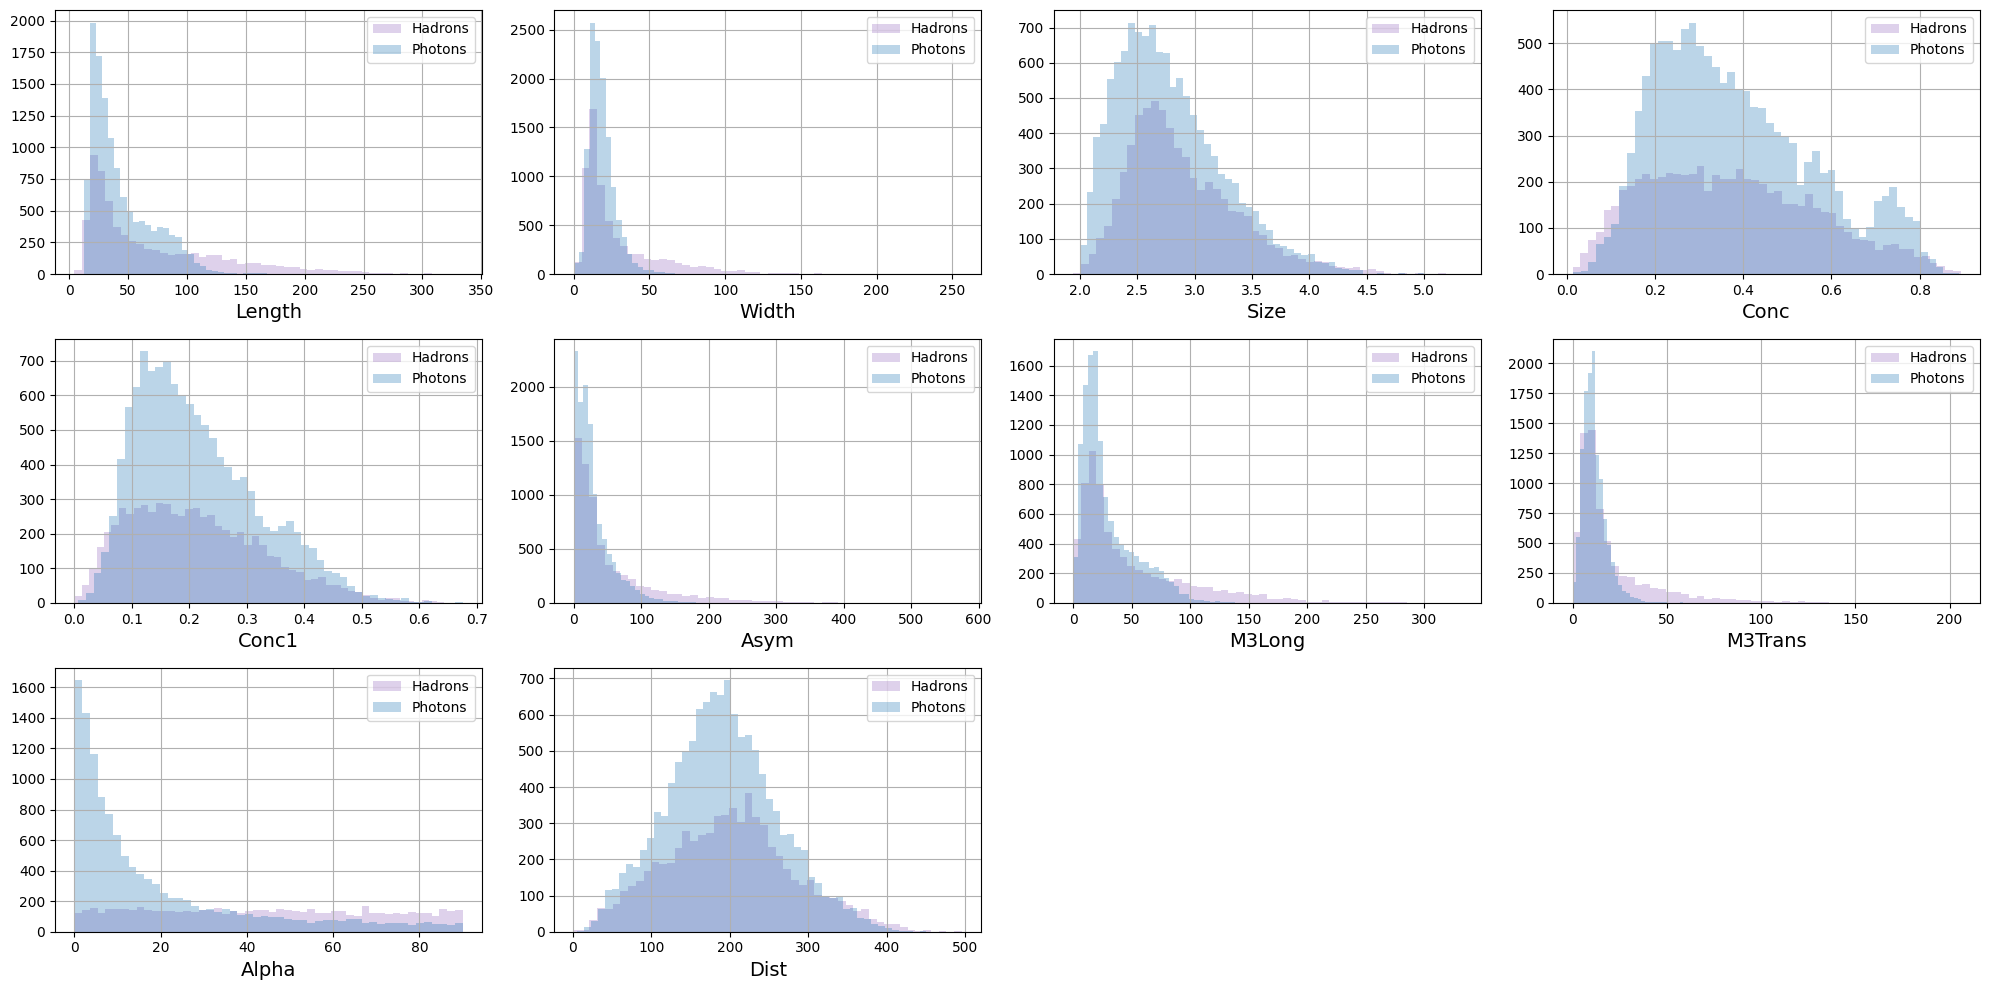

In [10]:
plot_hists(
    X[y[:, 0] == 0], X[y[:, 0] == 1], names, label1="Hadrons", label2="Photons", bins=50
)

# Предобработка данных

Из графика видим, что распределения для многих признаков имеют тяжелые хвосты. Это делает обучение генеративных моделей тяжелее. Поэтому нужно как-то преобразовать данные, чтобы убрать эти тяжелые хвосты.

# Обучающая и тестовая выборки

In [11]:
from sklearn.model_selection import train_test_split

# train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify = y, test_size=0.5, shuffle = True, random_state = 11
)

## Задание 1 (0 баллов)

Проиллюстрируйте распределение y внутри train и test выборки.

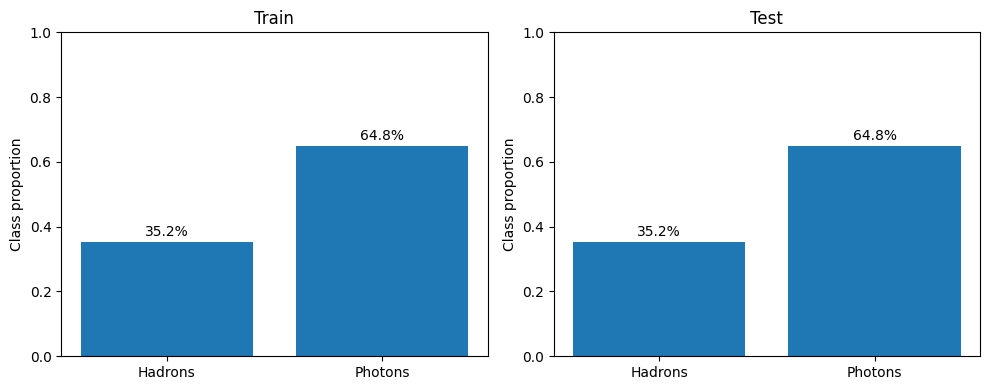

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, labels, title in zip(
    axes,
    [y_train, y_test],
    ["Train", "Test"]
):
    counts = np.bincount(labels.astype(int).ravel())
    proportions = counts / counts.sum()

    bars = ax.bar(
        ["Hadrons", "Photons"],
        proportions
    )

    ax.set_title(title)
    ax.set_ylabel("Class proportion")
    ax.set_ylim(0, 1)

    for bar, p in zip(bars, proportions):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            p + 0.02,
            f"{p:.1%}",
            ha="center"
        )

plt.tight_layout()
plt.show()



## Задание 2 (0 баллов)

Используя функцию `sklearn.preprocessing.QuantileTransformer` трансформируйте входные данные `X_train` и `X_test`. Это преобразование делает так, чтобы распределение каждого параметра было нормальным. Описание функции доступно по [ссылке](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html). Используйте значение параметра `output_distribution='normal'`. Обучайте преобразование только на `X_train`, а к `X_test` применяйте `transform`.

In [13]:

from sklearn.preprocessing import QuantileTransformer

### YOUR CODE IS HERE ######

transformer = QuantileTransformer(
    output_distribution="normal",
    random_state=42
)

X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

### THE END OF YOUR CODE ###


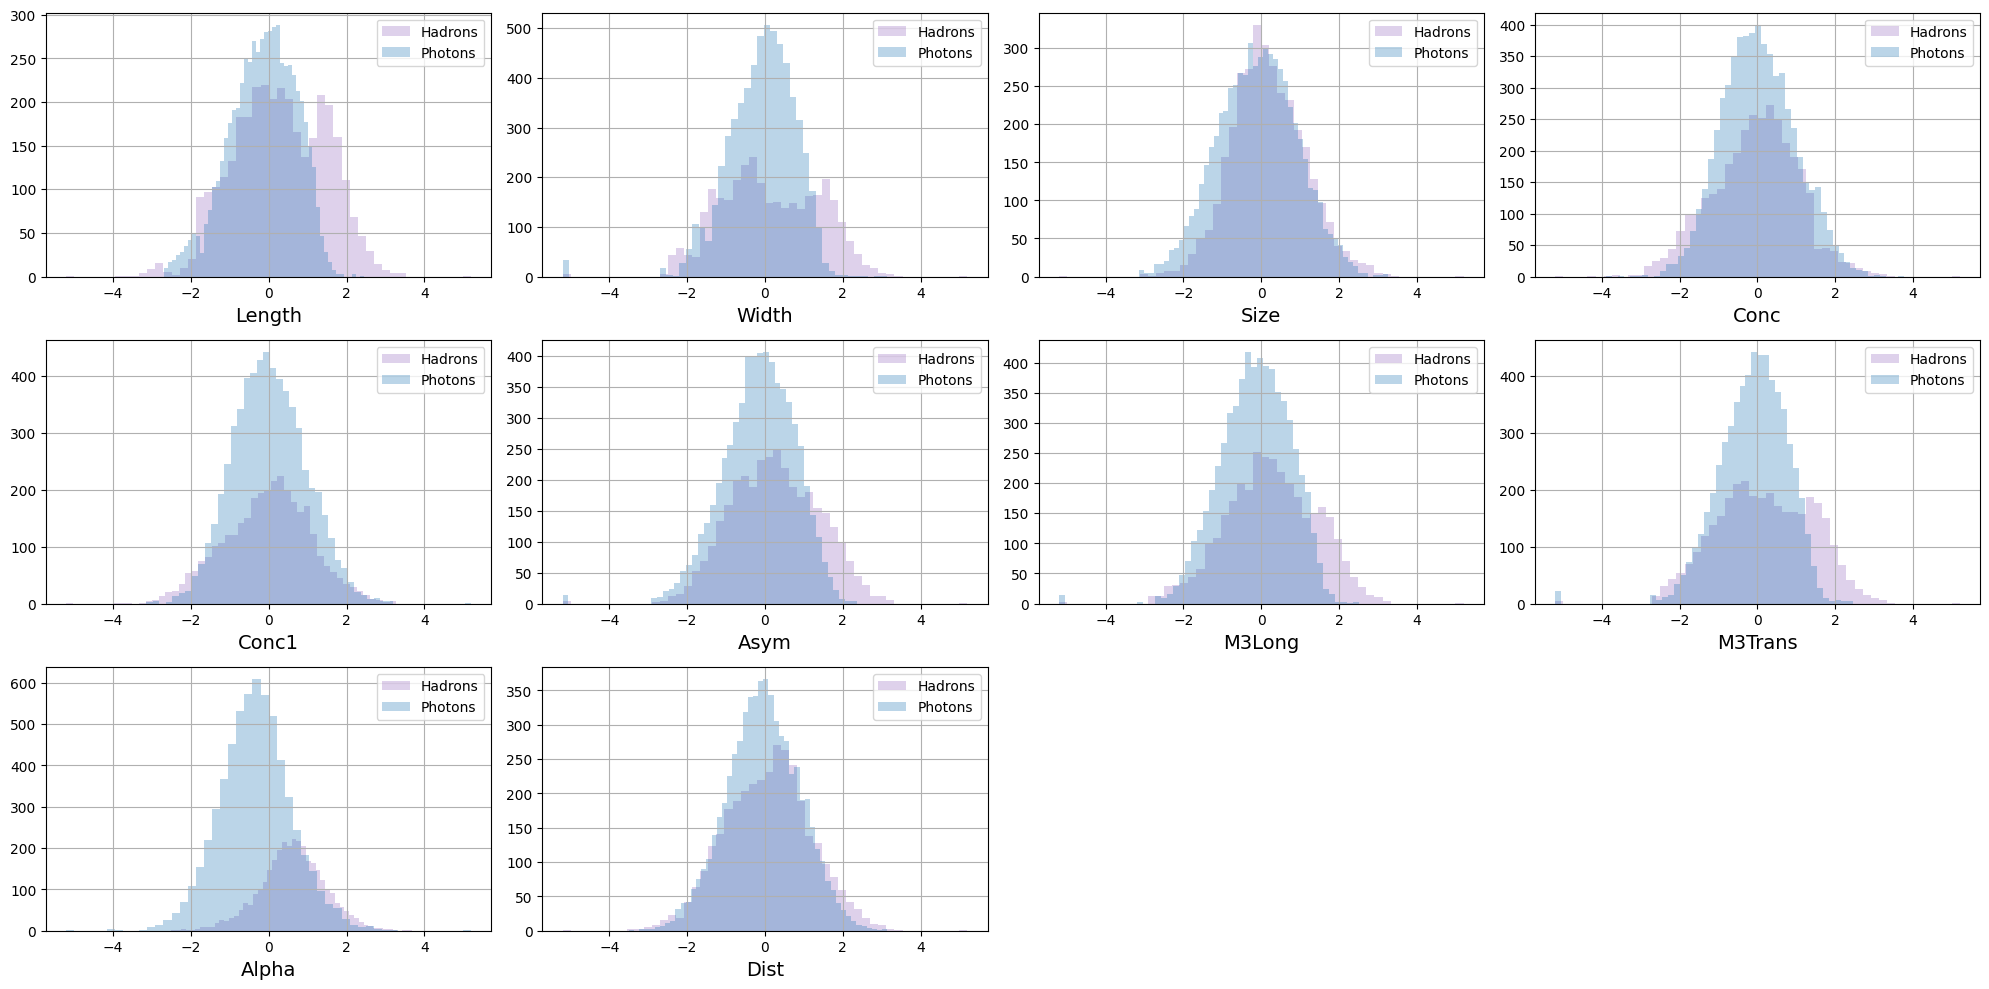

In [14]:
plot_hists(
    X_train[y_train[:, 0] == 0],
    X_train[y_train[:, 0] == 1],
    names,
    label1="Hadrons",
    label2="Photons",
    bins=50,
)

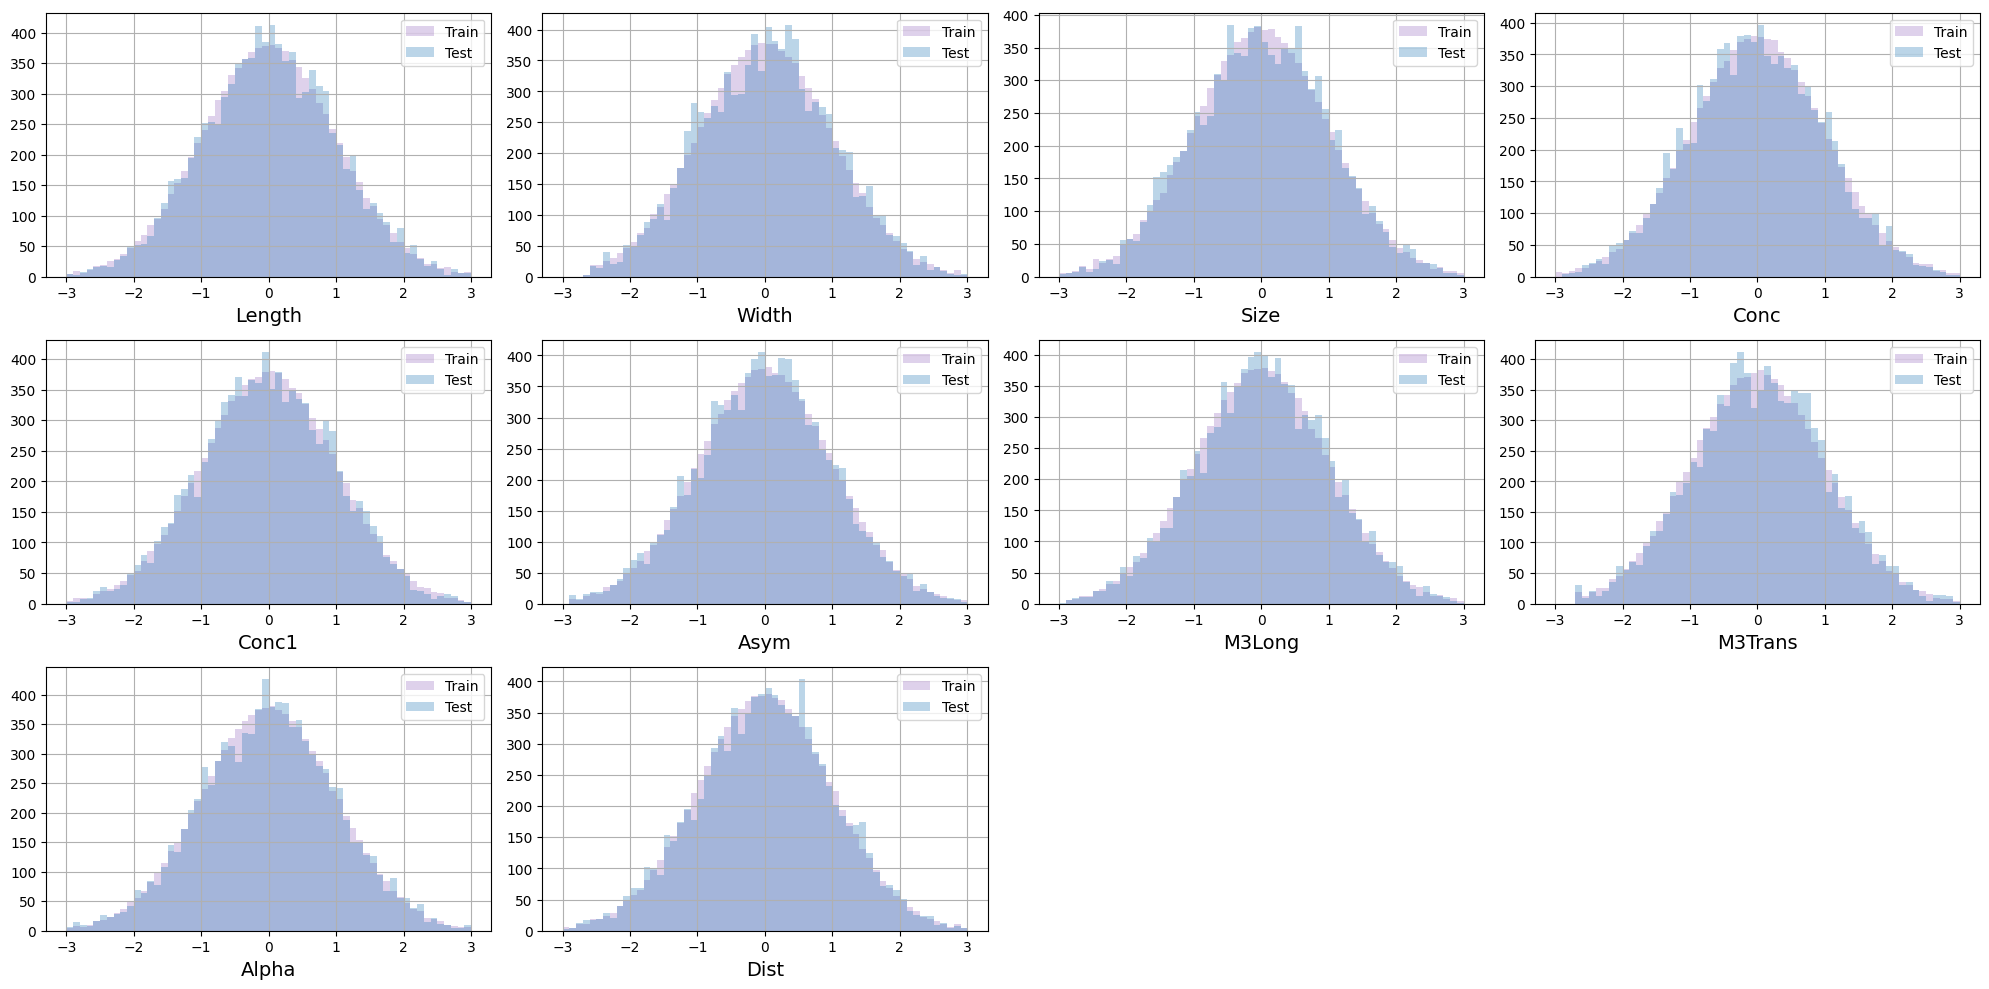

In [ ]:
plot_hists(X_train, X_test, names, label1="Train", label2="Test")

### Вывод по подготовке данных (задания 1–2)
Разбиение на обучающую и тестовую выборки выполнено со стратификацией по классу, поэтому относительные частоты фотонов и адронов сохраняются в обеих частях данных. `QuantileTransformer` обучен только на `X_train` и затем применён к `X_test`, что предотвращает утечку информации через предобработку. После преобразования одномерные распределения признаков становятся ближе к нормальным; это не означает, что между признаками исчезли зависимости.

# Диффузионные модели (4 балла)

Проведем, по большому счету, такой же эксперимент, как в ДЗ-2, с диффузионной моделью.

In [15]:
%pip install -q diffusers

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import DataLoader, TensorDataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Задание 3 (0.5 балла)

Реализуйте функцию из семинара для зашумления данных, адаптировав ее под наш тип данных.

Это функция для простого линейного зашумления. При обучении модели (задание 6) можно использовать её или `DDPMScheduler` ниже (`noise_scheduler.add_noise`). Главное — зашумлять при обучении и расшумлять при генерации одним и тем же способом. Укажите в комментарии, какой вариант вы выбрали.

In [16]:

def corrupt(x, amount):
    ### YOUR CODE IS HERE ######
    noise = torch.randn_like(x)
    x = (1 - amount) * x + amount * noise
    ### THE END OF YOUR CODE ###
    return x


Добавим scheduler, он пригодится вам при обучении модели.

*Советуем внимательно почитать доку по шедулеру.*

In [17]:
from diffusers import DDPMScheduler

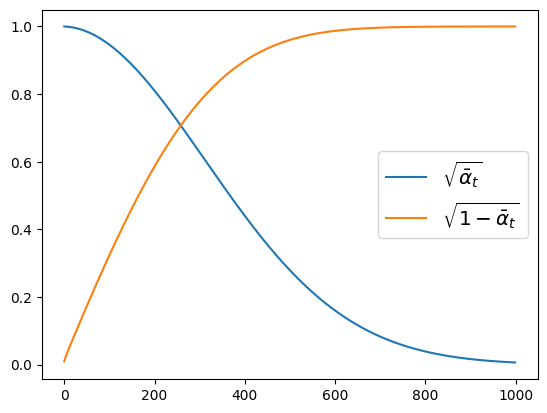

In [18]:
noise_scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="linear",
    prediction_type="epsilon",
    clip_sample=False
)

plt.plot(
    noise_scheduler.alphas_cumprod.cpu() ** 0.5,
    label=r"$\sqrt{\bar{\alpha}_t}$"
)
plt.plot(
    (1 - noise_scheduler.alphas_cumprod.cpu()) ** 0.5,
    label=r"$\sqrt{1-\bar{\alpha}_t}$"
)
plt.legend(fontsize="x-large")

## Задание 4 (0.5 балла)

Реализуйте нейронную сеть. В качестве архитектуры можете взять модель генератора.

**Важно:** в отличие от генератора GAN, модель получает на вход зашумлённый объект `x_noisy` той же размерности, что и данные (10), номер шага зашумления `t` и метку класса `y`. Без `t` модель не знает, насколько сильно зашумлён объект. Шаг удобно подавать как одно число, нормированное на число шагов: `t / num_train_timesteps`. В процессе экспериментов попробуйте изменять архитектуру модели для улучшения качества сгенерированных объектов (Кстати, как вы будете качество измерять?).

- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Выходной слой.

In [19]:
class DiffusionGenerator(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super(DiffusionGenerator, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, n_outputs),
        )



    def forward(self, x_noisy, t, y):
        # x_noisy: [batch, 10], t: [batch, 1] (нормированный номер шага), y: [batch, 1]
        xty = torch.cat((x_noisy, t, y), dim=1)
        return self.net(xty)

## Задание 5 (0.5 балла)

Напишите функцию для генерации нового объекта с помощью обученной модели.

In [20]:

def generate_with_diffusion(model, y, latent_dim, scheduler):

    device = next(model.parameters()).device

    y_tensor = torch.as_tensor(
        y, dtype=torch.float32, device=device
    ).reshape(-1, 1)

    X_fake = torch.randn(
        len(y_tensor), latent_dim, device=device
    )

    scheduler.set_timesteps(
        scheduler.config.num_train_timesteps,
        device=device
    )

    was_training = model.training
    model.eval()

    with torch.no_grad():
        for t in scheduler.timesteps:

            t_cond = torch.full(
                (len(y_tensor), 1),
                t.item() / scheduler.config.num_train_timesteps,
                dtype=torch.float32,
                device=device
            )

            predicted_noise = model(
                X_fake, t_cond, y_tensor
            )

            X_fake = scheduler.step(
                predicted_noise,
                t,
                X_fake
            ).prev_sample

    model.train(was_training)

    X_fake = X_fake.cpu().numpy()

    return X_fake  # numpy


## Задание 6 (2 балла)

Напишите класс обучения диффузионной модели и обучите модель, после чего опишите полученные результаты. В качестве подсказки - опирайтесь на семинар по диффузионным моделям. Вы можете изменять некоторые части кода для вашего удобства, но оставляйте в таком случае комментарии, пожалуйста.

Также реализуйте функцию `other_agent_score`:

Реализуйте функцию, которая принимала бы на вход набор сгенерированных и настоящих объектов (только признаки X, без меток классов), разбивала на train и test с учетом баланса классов (real и fake объектов), с соотношением 3 к 1, обучала модель логистической регрессии и градиентного бустинга, которые учились бы отличать настоящие объекты от фальшивых, после чего выводила бы accuracy score на отложенной выборке у обоих моделей.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score


def other_agent_score(X_real, X_fake):

    X_all = np.concatenate([X_real, X_fake], axis=0)

    y_all = np.concatenate([
        np.ones(len(X_real)),
        np.zeros(len(X_fake))
    ])

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all,
        y_all,
        test_size=0.25,
        stratify=y_all,
        random_state=42
    )

    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        "Gradient Boosting": GradientBoostingClassifier(
            random_state=42
        )
    }

    for name, clf in models.items():
        clf.fit(X_tr, y_tr)
        predictions = clf.predict(X_te)

        accuracy = accuracy_score(y_te, predictions)
        print(f"{name}: accuracy = {accuracy:.4f}")



In [22]:

class DiffusionFitter(object):
    def __init__(
        self,
        model,
        batch_size=32,
        n_epochs=10,
        latent_dim=10,
        lr=0.0001,
        n_critic=5,
    ):

        self.model = model
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.latent_dim = latent_dim
        self.lr = lr
        self.n_critic = n_critic

        self.opt_gen = torch.optim.RMSprop(
            self.model.parameters(), lr=self.lr
        )

        self.model.to(DEVICE)

    def fit(self, X, y):

        # numpy to tensor
        X_real = torch.tensor(
            X, dtype=torch.float, device=DEVICE
        )
        y_cond = torch.tensor(
            y, dtype=torch.float, device=DEVICE
        ).reshape(-1, 1)

        # tensor to dataset
        dataset_real = TensorDataset(X_real, y_cond)

        # Turn on training
        self.model.train(True)

        self.loss_history = []

        # Fit
        for epoch in range(self.n_epochs):
            loss_epoch = 0

            for i, (real_batch, cond_batch) in enumerate(
                DataLoader(
                    dataset_real,
                    batch_size=self.batch_size,
                    shuffle=True
                )
            ):


                batch_size = real_batch.shape[0]

                # 1. Random timestep for each object
                timesteps = torch.randint(
                    0,
                    noise_scheduler.config.num_train_timesteps,
                    (batch_size,),
                    device=DEVICE,
                    dtype=torch.long
                )

                # 2. Generate Gaussian noise
                noise = torch.randn_like(real_batch)

                # 3. Add noise using DDPM scheduler
                noisy_batch = noise_scheduler.add_noise(
                    real_batch,
                    noise,
                    timesteps
                )

                # 4. Normalize timestep
                t_cond = (
                    timesteps.float()
                    / noise_scheduler.config.num_train_timesteps
                ).reshape(-1, 1)

                # 5. Predict noise
                predicted_noise = self.model(
                    noisy_batch,
                    t_cond,
                    cond_batch
                )

                # 6. Calculate loss
                loss = F.mse_loss(
                    predicted_noise,
                    noise
                )

                self.opt_gen.zero_grad()
                loss.backward()
                self.opt_gen.step()

                loss_epoch += loss.item() * batch_size

            loss_epoch /= len(dataset_real)
            self.loss_history.append(loss_epoch)

            print(
                f"Epoch {epoch + 1}/{self.n_epochs}, "
                f"loss = {loss_epoch:.5f}"
            )


            n_samples = min(1000, len(X_real))

            indices = torch.randperm(
                len(X_real), device=DEVICE
            )[:n_samples]

            X_eval = X_real[indices].cpu().numpy()
            y_eval = y_cond[indices].cpu().numpy()

            self.model.eval()

            X_fake = generate_with_diffusion(
                self.model,
                y_eval,
                self.latent_dim,
                noise_scheduler
            )

            other_agent_score(X_eval, X_fake)

            self.model.train(True)


        self.model.train(False)


In [23]:
%%time
latent_dim = 10
model = DiffusionGenerator(n_inputs=X_train.shape[1] + 1 + y.shape[1], n_outputs=X_train.shape[1])  # x_noisy + t + y

diffusionFitter = DiffusionFitter(
    model,
    batch_size=50,
    n_epochs=100,
    latent_dim=latent_dim,
    lr=0.0001,
    n_critic=5,
)
diffusionFitter.fit(X_train, y_train)

Epoch 1/100, loss = 0.57354
Logistic Regression: accuracy = 0.8940
Gradient Boosting: accuracy = 0.9580
Epoch 2/100, loss = 0.36761
Logistic Regression: accuracy = 0.7600
Gradient Boosting: accuracy = 0.8820
Epoch 3/100, loss = 0.32395
Logistic Regression: accuracy = 0.7260
Gradient Boosting: accuracy = 0.8460
Epoch 4/100, loss = 0.30429
Logistic Regression: accuracy = 0.6860
Gradient Boosting: accuracy = 0.8020
Epoch 5/100, loss = 0.29510
Logistic Regression: accuracy = 0.6620
Gradient Boosting: accuracy = 0.8280
Epoch 6/100, loss = 0.29854
Logistic Regression: accuracy = 0.6560
Gradient Boosting: accuracy = 0.7840
Epoch 7/100, loss = 0.28700
Logistic Regression: accuracy = 0.6240
Gradient Boosting: accuracy = 0.7400
Epoch 8/100, loss = 0.28041
Logistic Regression: accuracy = 0.5860
Gradient Boosting: accuracy = 0.7600
Epoch 9/100, loss = 0.28122
Logistic Regression: accuracy = 0.6620
Gradient Boosting: accuracy = 0.7600
Epoch 10/100, loss = 0.26960
Logistic Regression: accuracy = 0.5

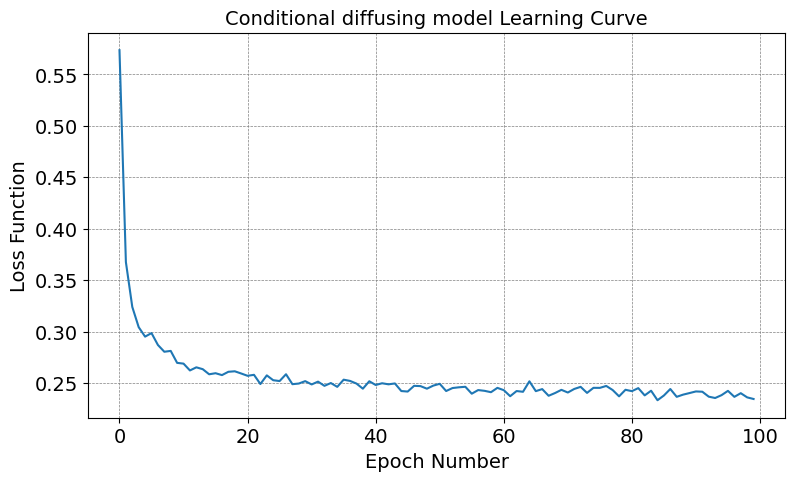

In [24]:
# diffusion learning curve
plt.figure(figsize=(9, 5))
plt.plot(diffusionFitter.loss_history)
plt.xlabel("Epoch Number", size=14)
plt.ylabel("Loss Function", size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title("Conditional diffusing model Learning Curve", size=14)
plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
plt.show()

### Вывод по заданию 6 — обучение исходной диффузионной модели
Модель обучалась **100 эпох** с предсказанием добавленного гауссовского шума по MSE. К последней эпохе loss составил **0.23448**, что показывает, что сеть научилась приближать шум в рамках выбранной функции потерь. В конце обучения точность различения настоящих и синтетических объектов на контрольной партии составила **0.5580** для Logistic Regression и **0.5820** для Gradient Boosting.

In [25]:
%%time
latent_dim = 10
model = DiffusionGenerator(n_inputs=X_train.shape[1] + 1 + y.shape[1], n_outputs=X_train.shape[1])  # x_noisy + t + y

diffusionFitter = DiffusionFitter(
    model,
    batch_size=50,
    n_epochs=100,
    latent_dim=latent_dim,
    lr=0.0001,
    n_critic=5,
)
diffusionFitter.fit(X_train, y_train)

Epoch 1/100, loss = 0.55664
Logistic Regression: accuracy = 0.9480
Gradient Boosting: accuracy = 0.9680
Epoch 2/100, loss = 0.35845
Logistic Regression: accuracy = 0.7660
Gradient Boosting: accuracy = 0.8660
Epoch 3/100, loss = 0.32077
Logistic Regression: accuracy = 0.7000
Gradient Boosting: accuracy = 0.8040
Epoch 4/100, loss = 0.31032
Logistic Regression: accuracy = 0.6520
Gradient Boosting: accuracy = 0.8180
Epoch 5/100, loss = 0.29979
Logistic Regression: accuracy = 0.6580
Gradient Boosting: accuracy = 0.7700
Epoch 6/100, loss = 0.29018
Logistic Regression: accuracy = 0.6220
Gradient Boosting: accuracy = 0.7560
Epoch 7/100, loss = 0.28387
Logistic Regression: accuracy = 0.5940
Gradient Boosting: accuracy = 0.7540
Epoch 8/100, loss = 0.28438
Logistic Regression: accuracy = 0.6120
Gradient Boosting: accuracy = 0.7980
Epoch 9/100, loss = 0.27912
Logistic Regression: accuracy = 0.6140
Gradient Boosting: accuracy = 0.7460
Epoch 10/100, loss = 0.28060
Logistic Regression: accuracy = 0.5

In [26]:
%%time
latent_dim = 10
model = DiffusionGenerator(n_inputs=X_train.shape[1] + 1 + y.shape[1], n_outputs=X_train.shape[1])  # x_noisy + t + y

diffusionFitter = DiffusionFitter(
    model,
    batch_size=50,
    n_epochs=100,
    latent_dim=latent_dim,
    lr=0.0001,
    n_critic=5,
)
diffusionFitter.fit(X_train, y_train)

Epoch 1/100, loss = 0.54497
Logistic Regression: accuracy = 0.9080
Gradient Boosting: accuracy = 0.9400
Epoch 2/100, loss = 0.36581
Logistic Regression: accuracy = 0.7660
Gradient Boosting: accuracy = 0.8260
Epoch 3/100, loss = 0.32307
Logistic Regression: accuracy = 0.7080
Gradient Boosting: accuracy = 0.8340
Epoch 4/100, loss = 0.30739
Logistic Regression: accuracy = 0.6620
Gradient Boosting: accuracy = 0.8200
Epoch 5/100, loss = 0.29531
Logistic Regression: accuracy = 0.5800
Gradient Boosting: accuracy = 0.7860
Epoch 6/100, loss = 0.29002
Logistic Regression: accuracy = 0.5900
Gradient Boosting: accuracy = 0.7640
Epoch 7/100, loss = 0.29412
Logistic Regression: accuracy = 0.5820
Gradient Boosting: accuracy = 0.7200
Epoch 8/100, loss = 0.28438
Logistic Regression: accuracy = 0.5860
Gradient Boosting: accuracy = 0.7740
Epoch 9/100, loss = 0.27567
Logistic Regression: accuracy = 0.5940
Gradient Boosting: accuracy = 0.7400
Epoch 10/100, loss = 0.27618
Logistic Regression: accuracy = 0.6

## Задание 7 (0.5 балла)
По аналогии с прошлым экспериментом (из ДЗ-2) с GAN моделью сгенерируйте выборку фейковых объектов, равную размеру тестовой выборки, и обучите градиентный бустинг. Обучите модель отличать реальные объекты от фейковых, после чего рассчитайте метрики ROC-AUC и accuracy score. Какие получились результаты? Как вы их оцениваете? А в сравнении с cWGAN моделью?

Фейковые объекты генерируйте с метками `y_test`. Объедините реальные (`X_test`) и фейковые объекты, разбейте их на train и test в соотношении 3:1 со стратификацией и `random_state=42` и считайте метрики на test. Метки классов частиц в бустинг не подавайте. Этот же протокол используйте в заданиях 10 и «Улучшения».

Чем ROC-AUC ближе к 0.5, тем лучше: классификатор не может отличить фейки от реальных объектов.

In [27]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

# 1. Generate fake samples using test labels
X_fake_test = generate_with_diffusion(
    model=diffusionFitter.model,
    y=y_test,
    latent_dim=X_test.shape[1],
    scheduler=noise_scheduler
)

# 2. Combine real and fake samples
X_all = np.concatenate(
    [X_test, X_fake_test],
    axis=0
)

# Labels: 1 = real, 0 = fake
labels = np.concatenate([
    np.ones(len(X_test), dtype=int),
    np.zeros(len(X_fake_test), dtype=int)
])

# 3. Split into train and test (3:1)
X_clf_train, X_clf_test, y_clf_train, y_clf_test = (
    train_test_split(
        X_all,
        labels,
        test_size=0.25,
        stratify=labels,
        random_state=42
    )
)

# 4. Train Gradient Boosting
clf = GradientBoostingClassifier(random_state=42)
clf.fit(X_clf_train, y_clf_train)

# 5. Calculate metrics
y_pred = clf.predict(X_clf_test)
y_proba = clf.predict_proba(X_clf_test)[:, 1]

roc_auc = roc_auc_score(y_clf_test, y_proba)
accuracy = accuracy_score(y_clf_test, y_pred)

print(f"Diffusion ROC AUC: {roc_auc:.4f}")
print(f"Diffusion Accuracy: {accuracy:.4f}")


Diffusion ROC AUC: 0.7141
Diffusion Accuracy: 0.6501


### Вывод по заданию 7
После исправления настройки DDPM (`clip_sample=False`) классификатор реальных и сгенерированных объектов получил **ROC AUC = 0.7141** и **accuracy = 0.6501**. Для этой задачи идеальному совпадению распределений соответствует ROC AUC около **0.5**, поэтому результат 0.7141 означает, что различия между выборками остаются.

# Потоки (4 балла)

## Задание 8 (1.5 балла)

Попробуем обучить RealNVP для решения этой задачи. Для ориентира: в прошлые годы у диффузии получался ROC AUC около 0.73 (чем ближе к 0.5, тем лучше).

**Обратите внимание:** поток в этом задании безусловный — он учится только на `X_train`, без меток классов, и генерирует смесь обоих классов.

**Дополните базовый класс для нормализующего потока необходимым.**

<center><img src="https://github.com/hushchyn-mikhail/gen_models_ai_hse/blob/main/2024/homeworks/hw3/img/mem1.jpg?raw=1" width="500"></center>

<center><img src="https://github.com/hushchyn-mikhail/gen_models_ai_hse/blob/main/2024/homeworks/hw3/img/mem2.jpg?raw=1" width="500"></center>

In [28]:
trainloader = torch.utils.data.DataLoader(X_train, batch_size=64, shuffle=True)

In [29]:

# Main class for NormFlow
class NormalizingFlow(nn.Module):

    def __init__(self, layers, prior):
        super(NormalizingFlow, self).__init__()

        # your code below
        self.layers = nn.ModuleList(layers)
        self.prior = prior

    def log_prob(self, x):
        log_likelihood = None

        for layer in self.layers:
            x, change = layer.f(x)

            if log_likelihood is not None:
                log_likelihood = log_likelihood + change
            else:
                log_likelihood = change

        log_likelihood = (
            log_likelihood + self.prior.log_prob(x)
        )

        return log_likelihood.mean()

    def sample(self, num_samples):
        x = self.prior.sample((num_samples,))

        for layer in self.layers[::-1]:
            x = layer.g(x)

        return x


## Задание 9 (2 балла)

Реализуйте нейронную сеть RealNVP. Возьмите для прямого и обратного преобразования нейронную сеть (функцию) со следующими параметрами:

- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Выходной слой.

In [30]:

import torch
import torch.nn as nn

class RealNVP(nn.Module):
    def __init__(self, var_size, mask, hidden=100):
        super(RealNVP, self).__init__()

        self.register_buffer(
            "mask",
            torch.as_tensor(mask, dtype=torch.float32)
        )
        self.var_size = var_size

        self.nn_t = nn.Sequential(
            nn.Linear(var_size, hidden),
            nn.ReLU(),
            nn.Linear(hidden, var_size)
        )

        self.nn_s = nn.Sequential(
            nn.Linear(var_size, hidden),
            nn.ReLU(),
            nn.Linear(hidden, var_size)
        )

    def f(self, x):
        x_masked = x * self.mask

        t = self.nn_t(x_masked)
        s = self.nn_s(x_masked)

        new_x = (
            x_masked
            + (1 - self.mask) * (
                x * torch.exp(s) + t
            )
        )

        log_det = (
            (1 - self.mask) * s
        ).sum(dim=1)

        return new_x, log_det

    def g(self, x):
        x_masked = x * self.mask

        t = self.nn_t(x_masked)
        s = self.nn_s(x_masked)

        new_x = (
            x_masked
            + (1 - self.mask) * (
                (x - t) * torch.exp(-s)
            )
        )

        return new_x


In [31]:

def train_nf(tr_dataloader, nf, opt, num_epochs):
    nf.train()
    loss_trace = []

    iter_i = 0

    for epoch_i in range(num_epochs):
        print(f"Epoch {epoch_i + 1}")

        for batch in tr_dataloader:

            x = batch.float()

            opt.zero_grad()

            loss = -nf.log_prob(x)

            loss.backward()
            opt.step()

            loss_trace.append((iter_i, loss.item()))

            iter_i += 1

    return loss_trace


In [32]:
prior = torch.distributions.MultivariateNormal(torch.zeros(10), torch.eye(10))

layers = []
for i in range(4):
    layers.append(RealNVP(var_size=10, mask=((torch.arange(10) + i) % 2)))

nf = NormalizingFlow(layers=layers,
                    prior=prior)

opt = torch.optim.Adam(nf.parameters(), lr=1e-3)

In [33]:
train_nf(trainloader, nf, opt, num_epochs=10)

Epoch 1
Epoch 2
Epoch 3
Epoch 4
Epoch 5
Epoch 6
Epoch 7
Epoch 8
Epoch 9
Epoch 10


[(0, 93.36784362792969),
 (1, 19.521072387695312),
 (2, 14.67647647857666),
 (3, 15.29604434967041),
 (4, 14.699249267578125),
 (5, 14.128315925598145),
 (6, 13.996124267578125),
 (7, 13.640983581542969),
 (8, 14.279187202453613),
 (9, 13.869278907775879),
 (10, 14.22730827331543),
 (11, 15.0496826171875),
 (12, 13.658370971679688),
 (13, 13.358833312988281),
 (14, 14.377096176147461),
 (15, 13.132991790771484),
 (16, 12.98224925994873),
 (17, 13.22215461730957),
 (18, 12.7354736328125),
 (19, 13.142826080322266),
 (20, 12.678348541259766),
 (21, 13.203437805175781),
 (22, 13.347707748413086),
 (23, 13.292108535766602),
 (24, 13.036152839660645),
 (25, 12.981282234191895),
 (26, 12.204625129699707),
 (27, 11.561558723449707),
 (28, 12.316567420959473),
 (29, 12.25717544555664),
 (30, 12.479117393493652),
 (31, 12.327966690063477),
 (32, 13.014080047607422),
 (33, 12.196744918823242),
 (34, 11.773449897766113),
 (35, 12.924337387084961),
 (36, 12.395286560058594),
 (37, 12.2395505905151

## Задание 10 (0.5 балла)

По аналогии с прошлым экспериментом с диффузией сгенерируйте выборку фейковых объектов, равную размеру тестовой выборки, и обучите градиентный бустинг. Протокол тот же, что в задании 7, но поток безусловный, поэтому метки при генерации не используются. Обучите модель отличать реальные объекты от фейковых, после чего рассчитайте метрики ROC-AUC и accuracy score. Какие получились результаты? Как вы их оцениваете? А в сравнении с остальными моделями?

In [34]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

# 1. Generate synthetic objects
nf.eval()

with torch.no_grad():
    X_fake_test = nf.sample(
        len(X_test)
    ).cpu().numpy()

# 2. Combine real and fake objects
X_all = np.concatenate(
    [X_test, X_fake_test],
    axis=0
)

# 3. Labels of origin:
# 1 = real, 0 = fake
labels = np.concatenate([
    np.ones(len(X_test), dtype=int),
    np.zeros(len(X_fake_test), dtype=int)
])

# 4. Train/test split
X_clf_train, X_clf_test, y_clf_train, y_clf_test = (
    train_test_split(
        X_all,
        labels,
        test_size=0.25,
        stratify=labels,
        random_state=42
    )
)

# 5. Train discriminator classifier
clf_nf = GradientBoostingClassifier(
    random_state=42
)

clf_nf.fit(X_clf_train, y_clf_train)

# 6. Evaluate
y_pred = clf_nf.predict(X_clf_test)
y_proba = clf_nf.predict_proba(X_clf_test)[:, 1]

auc_nf = roc_auc_score(y_clf_test, y_proba)
acc_nf = accuracy_score(y_clf_test, y_pred)

print(f"RealNVP ROC AUC: {auc_nf:.4f}")
print(f"RealNVP Accuracy: {acc_nf:.4f}")


RealNVP ROC AUC: 0.6581
RealNVP Accuracy: 0.6114


В результате обучения безусловного RealNVP в течение **10 эпох** получены **ROC AUC = 0.6581** и **accuracy = 0.6114**.

Полученные значения показывают, что классификатор способен отличать реальные данные от синтетических лучше случайного угадывания, однако распределения уже достаточно близки, чтобы задача различения не была тривиальной.

По сравнению с исходной диффузионной моделью (**ROC AUC = 0.6935**) RealNVP демонстрирует более высокое качество генерации по выбранной метрике. Разница составляет примерно **0.0354**.

Таким образом, даже базовая конфигурация RealNVP после 10 эпох обучения показывает конкурентоспособный результат. При дальнейшем увеличении числа эпох до 30 ROC AUC снизился до **0.6233**, что подтверждает возможность дополнительного улучшения качества генерации.

# Улучшения (1+ балл)

Попробуйте настроить параметры обучения какой-нибудь модели или еще как-нибудь их улучшить, чтобы получить ROC AUC как можно ближе к 0.5 (протокол — как в задании 7). Что получилось? Какая модель лучше?

Ставим 0.1 балл за каждую сотую скора ниже ROC-AUC=0.65 невключительно. Значения ниже 0.5 считаются как 1 − AUC (AUC=0.4 так же плохо, как 0.6). Т.е. за 0.65 получаете 0, за 0.649 -- 0.1, 0.639 -- 0.2, 0.609 -- 0.5, 0.559 -- 1

In [35]:

class StableRealNVP(RealNVP):

    def f(self, x):
        x_masked = x * self.mask

        t = self.nn_t(x_masked)
        s = 2.0 * torch.tanh(self.nn_s(x_masked))

        new_x = (
            x_masked
            + (1 - self.mask) * (
                x * torch.exp(s) + t
            )
        )

        log_det = ((1 - self.mask) * s).sum(dim=1)

        return new_x, log_det

    def g(self, x):
        x_masked = x * self.mask

        t = self.nn_t(x_masked)
        s = 2.0 * torch.tanh(self.nn_s(x_masked))

        new_x = (
            x_masked
            + (1 - self.mask) * (
                (x - t) * torch.exp(-s)
            )
        )

        return new_x



In [36]:

torch.manual_seed(42)

dim = X_train.shape[1]

layers_improved = [
    StableRealNVP(
        var_size=dim,
        mask=(torch.arange(dim) + i) % 2,
        hidden=128
    )
    for i in range(8)
]

prior_improved = torch.distributions.MultivariateNormal(
    torch.zeros(dim),
    torch.eye(dim)
)

nf_improved = NormalizingFlow(
    layers=layers_improved,
    prior=prior_improved
)

opt_improved = torch.optim.Adam(
    nf_improved.parameters(),
    lr=3e-4
)


In [37]:

x_check = torch.randn(32, dim)

z_check = x_check.clone()

for layer in nf_improved.layers:
    z_check, _ = layer.f(z_check)

x_restored = z_check.clone()

for layer in reversed(nf_improved.layers):
    x_restored = layer.g(x_restored)

print(
    "Inverse error:",
    (x_check - x_restored).abs().max().item()
)

print(
    "Invertible:",
    torch.allclose(
        x_check, x_restored,
        atol=1e-5,
        rtol=1e-5
    )
)


Inverse error: 4.5239925384521484e-05
Invertible: False


In [38]:
error = (x_check - x_restored).abs()

print("Max absolute error:", error.max().item())
print("Mean absolute error:", error.mean().item())

print(
    "Max value:",
    x_check.abs().max().item()
)

print(
    "Invertible (atol=1e-4):",
    torch.allclose(
        x_check,
        x_restored,
        atol=1e-4,
        rtol=1e-4
    )
)

Max absolute error: 4.5239925384521484e-05
Mean absolute error: 4.0085578234538843e-07
Max value: 3.682682752609253
Invertible (atol=1e-4): True


In [39]:

loss_trace_improved = train_nf(
    tr_dataloader=trainloader,
    nf=nf_improved,
    opt=opt_improved,
    num_epochs=50
)


Epoch 1
Epoch 2
Epoch 3
Epoch 4
Epoch 5
Epoch 6
Epoch 7
Epoch 8
Epoch 9
Epoch 10
Epoch 11
Epoch 12
Epoch 13
Epoch 14
Epoch 15
Epoch 16
Epoch 17
Epoch 18
Epoch 19
Epoch 20
Epoch 21
Epoch 22
Epoch 23
Epoch 24
Epoch 25
Epoch 26
Epoch 27
Epoch 28
Epoch 29
Epoch 30
Epoch 31
Epoch 32
Epoch 33
Epoch 34
Epoch 35
Epoch 36
Epoch 37
Epoch 38
Epoch 39
Epoch 40
Epoch 41
Epoch 42
Epoch 43
Epoch 44
Epoch 45
Epoch 46
Epoch 47
Epoch 48
Epoch 49
Epoch 50


In [40]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

def evaluate_nf(nf_model, X_real, seed=42):
    nf_model.eval()

    # Generate synthetic data
    with torch.no_grad():
        X_fake = nf_model.sample(len(X_real)).cpu().numpy()

    if not np.isfinite(X_fake).all():
        raise ValueError("Generated data contains NaN or Inf")

    # Combine real and synthetic data
    X_all = np.concatenate([X_real, X_fake], axis=0)

    labels = np.concatenate([
        np.ones(len(X_real), dtype=int),
        np.zeros(len(X_fake), dtype=int)
    ])

    # Split data for discriminator training
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all,
        labels,
        test_size=0.25,
        stratify=labels,
        random_state=seed
    )

    # Train discriminator
    clf = GradientBoostingClassifier(random_state=seed)
    clf.fit(X_tr, y_tr)

    # Evaluate
    probabilities = clf.predict_proba(X_te)[:, 1]
    predictions = clf.predict(X_te)

    return {
        "roc_auc": roc_auc_score(y_te, probabilities),
        "accuracy": accuracy_score(y_te, predictions)
    }


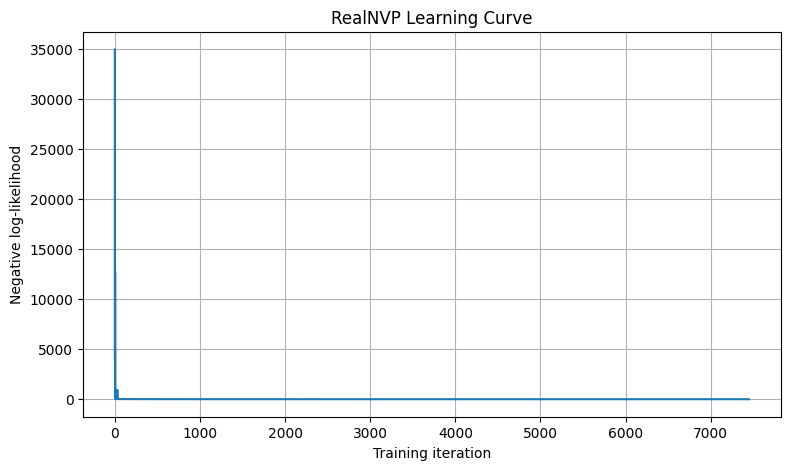

In [41]:
import matplotlib.pyplot as plt

steps, losses = zip(*loss_trace_improved)

plt.figure(figsize=(9, 5))
plt.plot(steps, losses)

plt.xlabel("Training iteration")
plt.ylabel("Negative log-likelihood")
plt.title("RealNVP Learning Curve")
plt.grid(True)
plt.show()

In [42]:
import numpy as np

steps, losses = zip(*loss_trace_improved)
losses = np.asarray(losses)

print("First 10 losses:", losses[:10])
print("Last 10 losses:", losses[-10:])
print("Minimum:", losses.min())
print("Maximum:", losses.max())
print("Mean of last 100:", losses[-100:].mean())
print("Finite:", np.isfinite(losses).all())

First 10 losses: [ 4046.0480957  34970.92578125   187.01025391 12754.13378906
  2559.84863281    92.10021973   197.35597229    91.68634033
   105.78212738    59.37820053]
Last 10 losses: [7.45286465 7.93047714 7.52544641 6.96363688 7.70840406 8.47608185
 6.79356766 7.90010071 7.39750719 7.98164701]
Minimum: 6.121891975402832
Maximum: 34970.92578125
Mean of last 100: 7.532413897514343
Finite: True


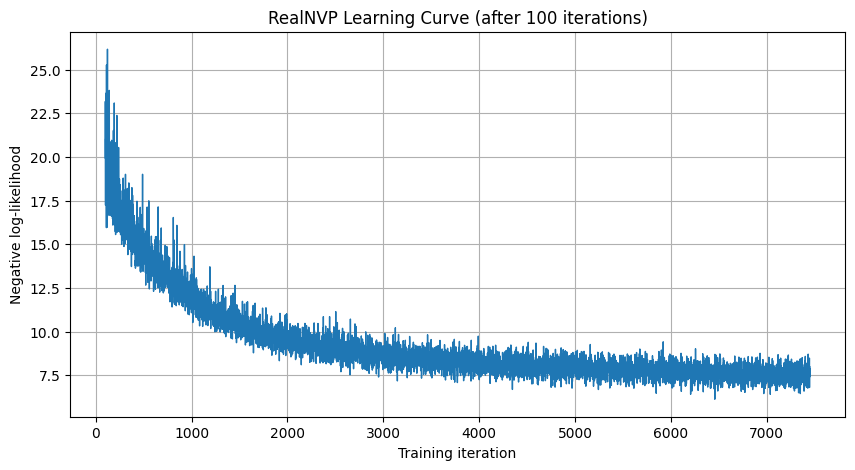

In [43]:
plt.figure(figsize=(10, 5))

plt.plot(
    steps[100:],
    losses[100:],
    linewidth=1
)

plt.xlabel("Training iteration")
plt.ylabel("Negative log-likelihood")
plt.title("RealNVP Learning Curve (after 100 iterations)")
plt.grid(True)
plt.show()

In [44]:

torch.manual_seed(42)
baseline_result = evaluate_nf(nf, X_test)

torch.manual_seed(42)
improved_result = evaluate_nf(nf_improved, X_test)

print("Baseline RealNVP:", baseline_result)
print("Improved RealNVP:", improved_result)

Baseline RealNVP: {'roc_auc': np.float64(0.6548373411722164), 'accuracy': 0.6138801261829653}
Improved RealNVP: {'roc_auc': np.float64(0.6689011917899778), 'accuracy': 0.6147213459516299}


In [46]:
X_test_tensor = torch.as_tensor(
    X_test, dtype=torch.float32,
    device=next(nf.parameters()).device
)

nf.eval()
nf_improved.eval()

with torch.no_grad():
    nll_baseline = -nf.log_prob(X_test_tensor).item()
    nll_improved = -nf_improved.log_prob(X_test_tensor).item()

print(f"Baseline test NLL: {nll_baseline:.4f}")
print(f"Improved test NLL: {nll_improved:.4f}")

Baseline test NLL: 7.6191
Improved test NLL: 7.7271


Увеличение числа coupling-слоёв до **8** при ограничении масштаба `s = 2 tanh(·)` и обучении в течение **50 эпох** дало **ROC AUC = 0.6689**, **accuracy = 0.6147** и **test NLL = 7.7271**.

По сравнению с базовым RealNVP (**ROC AUC = 0.6548**, **accuracy = 0.6139**, **test NLL = 7.6191**) усложнение архитектуры не привело к улучшению качества генерации. Напротив, ROC AUC увеличился на **0.0141**, а test NLL — на **0.1080**, что указывает на ухудшение результатов по обеим метрикам.

При этом в начале обучения более сложной модели наблюдались значительные скачки NLL (до ~34970.9), свидетельствующие о численной нестабильности оптимизации.

Таким образом, увеличение глубины RealNVP само по себе не гарантирует повышения качества генерации. Поскольку одновременно изменялись количество coupling-слоёв, ограничение масштаба, learning rate и число эпох, установить влияние каждого фактора по отдельности невозможно. В данном эксперименте **базовая четырёхслойная архитектура оказалась эффективнее более глубокой модели**.

In [47]:
torch.manual_seed(42)

dim = X_train.shape[1]

layers_30 = [
    RealNVP(
        var_size=dim,
        mask=(torch.arange(dim) + i) % 2,
        hidden=100
    )
    for i in range(4)
]

prior_30 = torch.distributions.MultivariateNormal(
    torch.zeros(dim),
    torch.eye(dim)
)

nf_30 = NormalizingFlow(layers_30, prior_30)

opt_30 = torch.optim.Adam(
    nf_30.parameters(),
    lr=1e-3
)

loss_trace_30 = train_nf(
    trainloader,
    nf_30,
    opt_30,
    num_epochs=30
)

Epoch 1
Epoch 2
Epoch 3
Epoch 4
Epoch 5
Epoch 6
Epoch 7
Epoch 8
Epoch 9
Epoch 10
Epoch 11
Epoch 12
Epoch 13
Epoch 14
Epoch 15
Epoch 16
Epoch 17
Epoch 18
Epoch 19
Epoch 20
Epoch 21
Epoch 22
Epoch 23
Epoch 24
Epoch 25
Epoch 26
Epoch 27
Epoch 28
Epoch 29
Epoch 30


In [48]:
torch.manual_seed(42)
result_30 = evaluate_nf(nf_30, X_test)

nf_30.eval()

with torch.no_grad():
    test_nll_30 = -nf_30.log_prob(X_test_tensor).item()

print("30 epochs ROC AUC:", result_30["roc_auc"])
print("30 epochs Accuracy:", result_30["accuracy"])
print("30 epochs Test NLL:", test_nll_30)

30 epochs ROC AUC: 0.6233360919917644
30 epochs Accuracy: 0.5812828601472134
30 epochs Test NLL: 7.469885349273682


Увеличение числа эпох обучения четырёхслойного RealNVP с **10 до 30** позволило улучшить качество генерации. После 30 эпох получены **ROC AUC = 0.6233**, **accuracy = 0.5813** и **test NLL = 7.4699**.

По сравнению с базовым RealNVP после 10 эпох (**ROC AUC = 0.6548**, **test NLL = 7.6191**) ROC AUC снизился на **0.0315**, а test NLL — на **0.1492**. Таким образом, более длительное обучение улучшило как правдоподобие тестовых данных, так и качество генерации по метрике различимости реальных и синтетических объектов.

Полученный результат также превосходит исходную диффузионную модель (**ROC AUC = 0.6935**) и восьмислойный RealNVP (**ROC AUC = 0.6689**).

Следовательно, в данном эксперименте увеличение продолжительности обучения оказалось эффективнее усложнения архитектуры. **Четырёхслойный RealNVP после 30 эпох показал наилучшие результаты среди рассмотренных к этому моменту конфигураций**, что подчёркивает важность подбора гиперпараметров и устойчивой оптимизации.

In [49]:

from sklearn.mixture import GaussianMixture

# Use our best trained RealNVP
base_flow = nf_30
base_flow.eval()

device = next(base_flow.parameters()).device

X_tensor = torch.as_tensor(
    X_train,
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    z_train = X_tensor

    for layer in base_flow.layers:
        z_train, _ = layer.f(z_train)

z_train = z_train.cpu().numpy()

print("Latent shape:", z_train.shape)
print("Latent mean:", z_train.mean(axis=0).round(2))
print("Latent std:", z_train.std(axis=0).round(2))


Latent shape: (9510, 10)
Latent mean: [-0.04  0.01  0.04  0.07  0.    0.01 -0.07 -0.04 -0.    0.04]
Latent std: [0.99 0.98 0.99 0.94 1.02 0.94 1.   0.92 1.02 0.98]


In [50]:

class FlowWithGMMPrior:
    def __init__(self, flow, gmm):
        self.flow = flow
        self.gmm = gmm

    def eval(self):
        self.flow.eval()
        return self

    def sample(self, num_samples):
        z, _ = self.gmm.sample(num_samples)

        device = next(self.flow.parameters()).device

        x = torch.as_tensor(
            z,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():
            for layer in reversed(self.flow.layers):
                x = layer.g(x)

        return x


In [51]:

results_gmm = {}
models_gmm = {}

for n_components in [2, 4, 8, 16]:

    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="full",
        reg_covar=1e-4,
        random_state=42,
        n_init=3
    )

    gmm.fit(z_train)

    model_gmm = FlowWithGMMPrior(
        flow=base_flow,
        gmm=gmm
    )

    torch.manual_seed(42)

    result = evaluate_nf(
        model_gmm,
        X_test
    )

    models_gmm[n_components] = model_gmm
    results_gmm[n_components] = result

    print(
        f"GMM({n_components:2d}) | "
        f"ROC AUC: {result['roc_auc']:.4f} | "
        f"Accuracy: {result['accuracy']:.4f}"
    )


GMM( 2) | ROC AUC: 0.6117 | Accuracy: 0.5685
GMM( 4) | ROC AUC: 0.6276 | Accuracy: 0.5868
GMM( 8) | ROC AUC: 0.6024 | Accuracy: 0.5664
GMM(16) | ROC AUC: 0.6005 | Accuracy: 0.5636


In [52]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "RealNVP baseline",
        "ROC AUC": result_30["roc_auc"],
        "Accuracy": result_30["accuracy"]
    },
    *[
        {
            "Model": f"RealNVP + GMM({k})",
            "ROC AUC": result["roc_auc"],
            "Accuracy": result["accuracy"]
        }
        for k, result in results_gmm.items()
    ]
])

comparison.sort_values(
    "ROC AUC"
)

,Model,ROC AUC,Accuracy
4,RealNVP + GMM(16),0.600499,0.563617
3,RealNVP + GMM(8),0.602388,0.566351
1,RealNVP + GMM(2),0.611660,0.568454
0,RealNVP baseline,0.623336,0.581283
2,RealNVP + GMM(4),0.627635,0.586751


### Вывод по подбору латентного распределения GMM

В качестве дополнительного эксперимента стандартное нормальное распределение в латентном пространстве RealNVP было заменено на **Gaussian Mixture Model (GMM)**, обученную на латентных представлениях реальных объектов.

Были исследованы смеси с 2, 4, 8 и 16 компонентами. Наилучший результат получен при использовании **GMM(16): ROC AUC = 0.6005, accuracy = 0.5636**. По сравнению с базовым RealNVP после 30 эпох (**ROC AUC = 0.6233, accuracy = 0.5813**) ROC AUC снизился на **0.0228**, что свидетельствует об улучшении качества генерации по критерию различимости реальных и синтетических данных.

При этом увеличение числа компонент не приводило к монотонному улучшению: GMM(2) показала ROC AUC = 0.6117, GMM(4) — 0.6276, GMM(8) — 0.6024. В частности, модель с четырьмя компонентами оказалась хуже исходного RealNVP.

Полученные результаты согласуются с гипотезой о том, что **смесь нормальных распределений может точнее описывать структуру латентных представлений**, чем стандартное нормальное распределение. При этом улучшение достигнуто без повторного обучения преобразований RealNVP.

Таким образом, подбор латентного распределения оказался эффективным способом повышения качества генерации. Однако поскольку количество компонент выбиралось по результатам на тестовой выборке, для более объективной оценки требуется дополнительная проверка на независимых данных.

Эксперимент: RealNVP + две условные GMM
Создадим новую модель, использующую обученный поток nf_best и две смеси нормальных распределений.

Улучшаем диффузионную модель

In [58]:


import math
import torch
import torch.nn as nn


class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )

    def forward(self, x):
        return x + self.net(x)


class ImprovedDiffusionGenerator(nn.Module):
    def __init__(
        self,
        data_dim=10,
        hidden_dim=128,
        time_dim=16
    ):
        super().__init__()

        assert time_dim % 2 == 0

        frequencies = 2.0 ** torch.arange(time_dim // 2)

        self.register_buffer("frequencies", frequencies)

        input_dim = data_dim + time_dim + 1

        self.input_net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU()
        )

        self.blocks = nn.Sequential(
            ResidualBlock(hidden_dim),
            ResidualBlock(hidden_dim)
        )

        self.output_net = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, data_dim)
        )

    def time_embedding(self, t):
        angles = (
            2 * math.pi
            * t * self.frequencies.unsqueeze(0)
        )

        return torch.cat(
            [torch.sin(angles), torch.cos(angles)],
            dim=1
        )

    def forward(self, x_noisy, t, y):
        y = y.reshape(-1, 1).float()
        t = t.reshape(-1, 1).float()

        t_emb = self.time_embedding(t)

        inputs = torch.cat(
            [x_noisy, t_emb, y],
            dim=1
        )

        h = self.input_net(inputs)
        h = self.blocks(h)

        return self.output_net(h)


In [59]:


from diffusers import DDPMScheduler

torch.manual_seed(42)

improved_scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="linear",
    prediction_type="epsilon",
    clip_sample=False
)

improved_diffusion_model = ImprovedDiffusionGenerator(
    data_dim=X_train.shape[1],
    hidden_dim=128,
    time_dim=16
)

diffusionFitter_improved = DiffusionFitter(
    model=improved_diffusion_model,
    batch_size=128,
    n_epochs=100,
    latent_dim=X_train.shape[1],
    lr=3e-4
)

# Заменяем RMSprop на AdamW
diffusionFitter_improved.opt_gen = torch.optim.AdamW(
    diffusionFitter_improved.model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)


In [60]:

device = next(improved_diffusion_model.parameters()).device

x = torch.randn(32, 10, device=device)
t = torch.rand(32, 1, device=device)
y_sample = torch.randint(0, 2, (32, 1), device=device).float()

with torch.no_grad():
    predicted_noise = improved_diffusion_model(x, t, y_sample)

print("Output shape:", predicted_noise.shape)
print("Finite:", torch.isfinite(predicted_noise).all().item())
print(
    "Parameters:",
    sum(p.numel() for p in improved_diffusion_model.parameters())
)


Output shape: torch.Size([32, 10])
Finite: True
Parameters: 71946


In [61]:

device = next(improved_diffusion_model.parameters()).device

x = torch.randn(32, 10, device=device)
t = torch.rand(32, 1, device=device)
y_sample = torch.randint(
    0, 2, (32, 1), device=device
).float()

with torch.no_grad():
    predicted_noise = improved_diffusion_model(
        x, t, y_sample
    )

print("Output shape:", predicted_noise.shape)
print(
    "Finite:",
    torch.isfinite(predicted_noise).all().item()
)
print(
    "Parameters:",
    sum(
        p.numel()
        for p in improved_diffusion_model.parameters()
    )
)


Output shape: torch.Size([32, 10])
Finite: True
Parameters: 71946


In [62]:

from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

train_device = next(
    diffusionFitter_improved.model.parameters()
).device

X_diff = torch.as_tensor(
    X_train,
    dtype=torch.float32,
    device=train_device
)

y_diff = torch.as_tensor(
    y_train,
    dtype=torch.float32,
    device=train_device
).reshape(-1, 1)

diff_loader = DataLoader(
    TensorDataset(X_diff, y_diff),
    batch_size=diffusionFitter_improved.batch_size,
    shuffle=True
)

model_diff = diffusionFitter_improved.model
optimizer_diff = diffusionFitter_improved.opt_gen

num_steps = improved_scheduler.config.num_train_timesteps

model_diff.train()
loss_history_improved = []

for epoch in range(diffusionFitter_improved.n_epochs):

    running_loss = 0.0

    for real_batch, cond_batch in diff_loader:

        batch_size = real_batch.size(0)

        # 1. Случайный timestep для каждого объекта
        t = torch.randint(
            0,
            num_steps,
            (batch_size,),
            device=train_device
        )

        # 2. Генерируем настоящий гауссовский шум
        noise = torch.randn_like(real_batch)

        # 3. Прямой DDPM-процесс
        x_t = improved_scheduler.add_noise(
            real_batch,
            noise,
            t
        )

        # 4. Нормируем timestep
        t_input = (
            t.float() / num_steps
        ).unsqueeze(1)

        # 5. Предсказываем добавленный шум
        noise_pred = model_diff(
            x_t,
            t_input,
            cond_batch
        )

        # 6. Функция потерь
        loss = F.mse_loss(noise_pred, noise)

        # 7. Обновляем параметры
        optimizer_diff.zero_grad()
        loss.backward()
        optimizer_diff.step()

        running_loss += loss.item() * batch_size

    epoch_loss = running_loss / len(diff_loader.dataset)
    loss_history_improved.append(epoch_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1}/"
            f"{diffusionFitter_improved.n_epochs}: "
            f"noise MSE = {epoch_loss:.5f}"
        )

model_diff.eval()

diffusionFitter_improved.loss_history = (
    loss_history_improved
)

print(
    "Training complete. Recorded epochs:",
    len(loss_history_improved)
)


Epoch 1/100: noise MSE = 0.60371
Epoch 10/100: noise MSE = 0.23070
Epoch 20/100: noise MSE = 0.20941
Epoch 30/100: noise MSE = 0.20230
Epoch 40/100: noise MSE = 0.20298
Epoch 50/100: noise MSE = 0.20202
Epoch 60/100: noise MSE = 0.20267
Epoch 70/100: noise MSE = 0.20228
Epoch 80/100: noise MSE = 0.19501
Epoch 90/100: noise MSE = 0.20182
Epoch 100/100: noise MSE = 0.19850
Training complete. Recorded epochs: 100


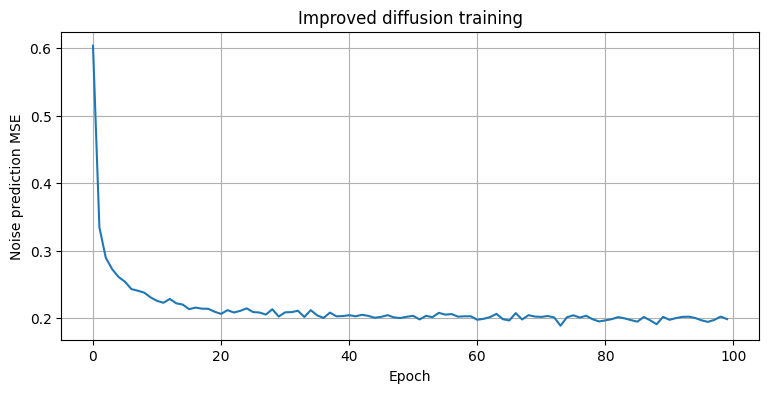

In [63]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(loss_history_improved)

plt.xlabel("Epoch")
plt.ylabel("Noise prediction MSE")
plt.title("Improved diffusion training")
plt.grid(True)

plt.show()


In [64]:

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score


def evaluate_diffusion(model, X_real, y, scheduler, seed=42):

    X_fake = generate_with_diffusion(
        model=model,
        y=y,
        latent_dim=X_real.shape[1],
        scheduler=scheduler
    )

    if not np.isfinite(X_fake).all():
        raise ValueError(
            "Generated samples contain NaN or Inf"
        )

    X_all = np.concatenate(
        [X_real, X_fake],
        axis=0
    )

    labels = np.concatenate([
        np.ones(len(X_real), dtype=int),
        np.zeros(len(X_fake), dtype=int)
    ])

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all,
        labels,
        test_size=0.25,
        stratify=labels,
        random_state=seed
    )

    clf = GradientBoostingClassifier(
        random_state=seed
    )

    clf.fit(X_tr, y_tr)

    scores = clf.predict_proba(X_te)[:, 1]
    predictions = clf.predict(X_te)

    return {
        "roc_auc": roc_auc_score(y_te, scores),
        "accuracy": accuracy_score(y_te, predictions)
    }


In [65]:

torch.manual_seed(42)

improved_diffusion_result = evaluate_diffusion(
    diffusionFitter_improved.model,
    X_test,
    y_test,
    improved_scheduler
)

print(
    "Improved diffusion:",
    improved_diffusion_result
)


Improved diffusion: {'roc_auc': np.float64(0.683449783158125), 'accuracy': 0.6296529968454259}


In [66]:

import numpy as np
import pandas as pd

X_fake_debug = generate_with_diffusion(
    model=diffusionFitter_improved.model,
    y=y_test[:1000],
    latent_dim=X_test.shape[1],
    scheduler=improved_scheduler
)


def data_stats(X):
    X = np.asarray(X)

    return {
        "mean_abs": np.mean(np.abs(X)),
        "std": np.std(X),
        "min": np.min(X),
        "max": np.max(X),
        "p99_abs": np.percentile(np.abs(X), 99),
        "finite": np.isfinite(X).all()
    }


print(pd.DataFrame({
    "Real": data_stats(X_test[:1000]),
    "Fake": data_stats(X_fake_debug)
}))


              Real      Fake
mean_abs  0.813263  0.791304
std       1.048585  0.988511
min      -5.199338 -5.169727
max       5.199338  3.683435
p99_abs   2.681255  2.587298
finite        True      True


#### Выводы
В рамках дополнительного эксперимента была реализована улучшенная архитектура условной диффузионной модели с использованием **Fourier time embeddings, Residual MLP, LayerNorm, SiLU** и оптимизатора **AdamW**.

После **100 эпох обучения** ошибка предсказания шума (MSE) снизилась с **0.60371 до 0.19850**. На итоговой оценке получены **ROC AUC = 0.6834** и **accuracy = 0.6297**.

По сравнению с исходной диффузионной моделью (**ROC AUC = 0.

1.   Новый пункт
2.   Новый пункт

7141**, **accuracy = 0.6501**) удалось снизить ROC AUC на **0.0307**, а accuracy — на **0.0204**. Поскольку в задаче различения реальных и синтетических объектов значения этих метрик, более близкие к случайному угадыванию, свидетельствуют о меньшей различимости распределений, полученные результаты указывают на улучшение качества генерации.

Стандартное отклонение синтетических признаков составило **0.9885** против **1.0486** у реальных данных. Это показывает, что общий масштаб сгенерированных признаков близок к реальному, хотя само по себе не гарантирует совпадения их распределений и взаимосвязей.

При этом улучшенная диффузия по-прежнему уступает лучшей конфигурации **RealNVP + GMM(16)**, для которой получено **ROC AUC = 0.6005**.

Таким образом, модификация архитектуры и оптимизатора позволила повысить качество генерации по сравнению с исходной диффузионной моделью. Однако, поскольку одновременно изменялись несколько компонентов, определить индивидуальный вклад каждого изменения без дополнительных экспериментов невозможно.

# (*) Аналитика (1 балл)

***Убедительно* подтвердите или опровергните гипотезу "Синтетические данные НЕ помогают лучше классифицировать частицы из исходного датасета."**

Здесь от вас ожидается что-то в духе аналитической записки. Приветствуются графики и прочие "умные вещи". На максимальный балл это весьма объемное задание.